# Travel-time convexification and dual recovery

Changing speed to segment time makes the fuel objective reciprocal-convex and the arrival windows linear. The full constant fuel term is retained. A nearly active nonnegative KKT fit refines the final feasible dual witness.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Independent two-segment oracle

In [2]:
from optimization_lab.barrier import speed_barrier
p=dict(d=[1.,2.],a=4.,b=3.,c=16.,smin=[.5,.5],smax=[5.,5.],tau_min=[0.,0.],tau_max=[10.,10.])
r=speed_barrier(p)
assert np.allclose(r["speed"],[2.,2.],atol=1e-5)
assert abs(r["certificate"]["objective"]-57.)<1e-5
print(r["certificate"]["gap"])

8.004768403679918e-09


## Full original problem

In [3]:
m=read("results/reference/convex/speed/metrics.json")
{k:{q:v for q,v in m[k].items() if q!="multipliers"} for k in ["certificate","owned_certificate"]}

{'certificate': {'objective': 2617.825193571288,
  'dual_objective': 2617.8251933025617,
  'gap': 2.687261257960927e-07,
  'constraint_violation': 1.5697310118412133e-10,
  'stationarity_residual': 1.731043378683239e-05,
  'complementarity_max': 1.1626635741191501e-09},
 'owned_certificate': {'objective': 2617.825193586634,
  'dual_objective': 2617.8251935525213,
  'gap': 3.4112872526748106e-08,
  'constraint_violation': 0.0,
  'stationarity_residual': 4.7331916164239374e-08,
  'complementarity_max': 9.99998745337747e-10}}

## Physical schedule

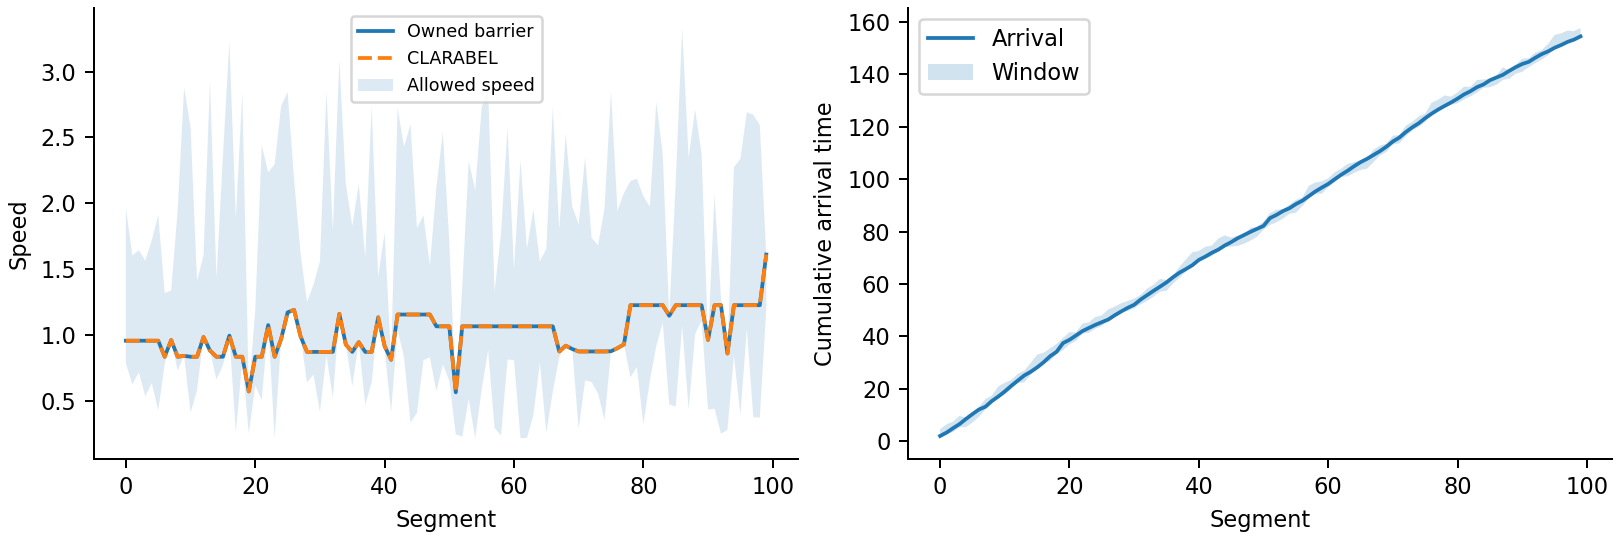

In [4]:
figure("speed_schedule")

## Dual convergence

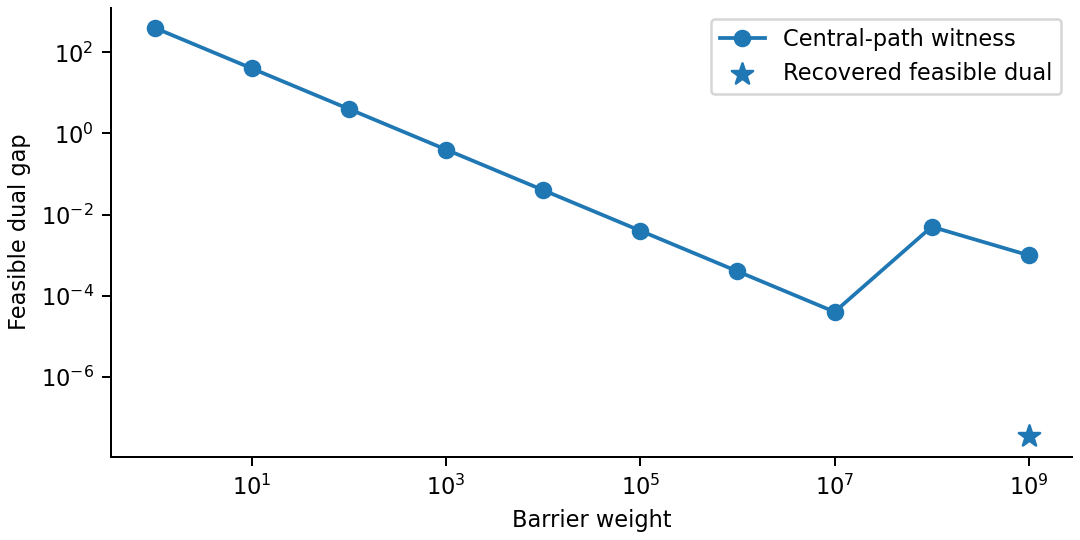

In [5]:
figure("speed_certificate")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.